# Module 6 — End-to-End Multimodal RAG

Combine document ingestion, layout extraction, image captioning, CLIP embeddings, FAISS retrieval, and grounded answer generation in one pipeline.

## 1. Install dependencies

Install the PDF parsing, image processing, embedding, vector search, and VLM libraries.

In [1]:
!apt-get -qq update
!apt-get -qq install -y poppler-utils tesseract-ocr
!pip -q install "unstructured[pdf]" pymupdf pillow pandas matplotlib faiss-cpu transformers accelerate sentencepiece qwen-vl-utils

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package poppler-utils.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../poppler-utils_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking poppler-utils (24.02.0-1ubuntu9.11) ...
Setting up poppler-utils (24.02.0-1ubuntu9.11) ...
Processing triggers for man-db (2.12.0-4build2) ...
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [3]:
!pip install -q langchain-text-splitters

## 2. Imports and device

Import the libraries used throughout the pipeline and check the available compute device.

In [4]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import faiss
import fitz
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display
from unstructured.partition.pdf import partition_pdf
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import (
    CLIPProcessor, CLIPModel,
    Blip2Processor, Blip2ForConditionalGeneration,
    AutoProcessor, Qwen3VLForConditionalGeneration
)
from google.colab import files

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


## 3. Upload a document

Upload a PDF containing text, tables, and images or figures.

In [5]:
uploaded = files.upload()
pdf_files = [name for name in uploaded if name.lower().endswith(".pdf")]
if not pdf_files:
    raise ValueError("Upload at least one PDF file.")

pdf_path = Path(pdf_files[0])
print("Document:", pdf_path.name)

Saving sample_multimodal_invoice.pdf to sample_multimodal_invoice.pdf
Document: sample_multimodal_invoice.pdf


## 4. Render PDF pages

Render each page to an image so the original layout can be inspected.

In [6]:
render_dir = Path("rag_rendered_pages")
render_dir.mkdir(exist_ok=True)

pdf_doc = fitz.open(pdf_path)
page_images = []
for page_number, page in enumerate(pdf_doc, start=1):
    pix = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5), alpha=False)
    image_path = render_dir / f"page_{page_number}.png"
    pix.save(image_path)
    page_images.append(image_path)

print("Pages rendered:", len(page_images))

Pages rendered: 2


## 5. Parse document layout

Use Unstructured's high-resolution strategy to extract document elements, infer table structure, and save image and table regions.

In [7]:
extracted_image_dir = Path("rag_extracted_images")
extracted_image_dir.mkdir(exist_ok=True)

elements = partition_pdf(
    filename=str(pdf_path),
    strategy="hi_res",
    infer_table_structure=True,
    extract_images_in_pdf=True,
    extract_image_block_types=["Image", "Table"],
    extract_image_block_output_dir=str(extracted_image_dir)
)

print("Elements extracted:", len(elements))
print("Image files extracted:", len(list(extracted_image_dir.rglob("*"))))

yolox_l0.05.onnx: reconstructing file:   0%|          |  0.00B /  217MB            

yolox_l0.05.onnx: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/274 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

Elements extracted: 35
Image files extracted: 6


## 6. Convert extracted elements to records

Store text, tables, page numbers, element types, and bounding boxes with the source document.

In [8]:
element_records = []

for element_id, element in enumerate(elements):
    category = element.category
    coordinates = element.metadata.coordinates
    bbox = None

    if coordinates is not None:
        points = coordinates.points
        xs = [point[0] for point in points]
        ys = [point[1] for point in points]
        bbox = {"x1": min(xs), "y1": min(ys), "x2": max(xs), "y2": max(ys)}

    element_records.append({
        "element_id": element_id,
        "source_doc": pdf_path.name,
        "page": element.metadata.page_number,
        "type": "table" if category == "Table" else category.lower(),
        "text": str(element).strip(),
        "bbox": bbox
    })

elements_df = pd.DataFrame(element_records)
display(elements_df[["element_id", "page", "type", "text"]].head(15))

,element_id,page,type,text
0,0,1,image,MERIDIAN RESEARCH LABS
1,1,1,title,TAX INVOICE
2,2,1,narrativetext,Original for recipient
3,3,1,uncategorizedtext,Supplier
4,4,1,title,Supplier
5,5,1,narrativetext,"Meridian Research Labs Pvt. Ltd. Plot 18, Sect..."
6,6,1,title,Bill To
7,7,1,narrativetext,"Northstar Office Supplies Unit 402, Tech Park ..."
8,8,1,table,Invoice No. MRL-2026-1184 Invoice Date 18 Nov ...
9,9,1,title,Items and Services


## 7. Split text and tables into chunks

Create compact chunks that retain source page metadata and fit the CLIP text encoder's limited input length.

In [9]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=220,
    chunk_overlap=35,
    separators=["\\n\\n", "\\n", ". ", " ", ""]
)
table_splitter = RecursiveCharacterTextSplitter(
    chunk_size=220,
    chunk_overlap=35,
    separators=["\\n", "|", " ", ""]
)

text_chunks = []
for record in element_records:
    if record["type"] in {"title", "narrativetext", "text", "listitem", "table"} and record["text"]:
        splitter = table_splitter if record["type"] == "table" else text_splitter
        for chunk_no, chunk in enumerate(splitter.split_text(record["text"])):
            text_chunks.append({
                "chunk_id": f"{record['element_id']}_{chunk_no}",
                "source_doc": record["source_doc"],
                "page": record["page"],
                "content_type": record["type"],
                "text": chunk
            })

print("Text/table chunks:", len(text_chunks))
display(pd.DataFrame(text_chunks).head(10))

Text/table chunks: 36


,chunk_id,source_doc,page,content_type,text
0,1_0,sample_multimodal_invoice.pdf,1,title,TAX INVOICE
1,2_0,sample_multimodal_invoice.pdf,1,narrativetext,Original for recipient
2,4_0,sample_multimodal_invoice.pdf,1,title,Supplier
3,5_0,sample_multimodal_invoice.pdf,1,narrativetext,"Meridian Research Labs Pvt. Ltd. Plot 18, Sect..."
4,6_0,sample_multimodal_invoice.pdf,1,title,Bill To
5,7_0,sample_multimodal_invoice.pdf,1,narrativetext,"Northstar Office Supplies Unit 402, Tech Park ..."
6,8_0,sample_multimodal_invoice.pdf,1,table,Invoice No. MRL-2026-1184 Invoice Date 18 Nov ...
7,9_0,sample_multimodal_invoice.pdf,1,title,Items and Services
8,10_0,sample_multimodal_invoice.pdf,1,table,# Description HSN/SAC Qty Unit Price (n) Amoun...
9,10_1,sample_multimodal_invoice.pdf,1,table,"switch, 24-port managed 8517 1 24,750.00 24,75..."


## 8. Collect extracted images

Load image and table-region files as RGB images and retain their source document and file paths.

Images available: 6


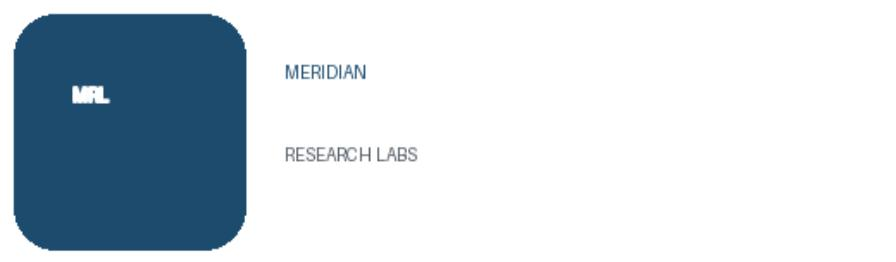

In [10]:
image_extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp"}
image_paths = sorted(
    path for path in extracted_image_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
)

image_items = []
for image_id, image_path in enumerate(image_paths):
    try:
        image_items.append({
            "image_id": image_id,
            "source_doc": pdf_path.name,
            "image_path": str(image_path),
            "image": Image.open(image_path).convert("RGB")
        })
    except Exception as error:
        print("Skipped:", image_path.name, error)

print("Images available:", len(image_items))
if image_items:
    display(image_items[0]["image"])

## 9. Generate captions with BLIP-2

Load the BLIP-2 captioning model and generate a caption for each extracted visual region. This model may require a GPU with sufficient memory.

In [11]:
caption_model_id = "Salesforce/blip2-opt-2.7b"
caption_processor = Blip2Processor.from_pretrained(caption_model_id)
caption_model = Blip2ForConditionalGeneration.from_pretrained(
    caption_model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None
)
if device == "cpu":
    caption_model = caption_model.to(device)

@torch.inference_mode()
def generate_caption(image, max_new_tokens=80):
    inputs = caption_processor(images=image, return_tensors="pt")
    inputs = {key: value.to(caption_model.device) for key, value in inputs.items()}
    if "pixel_values" in inputs:
        inputs["pixel_values"] = inputs["pixel_values"].to(dtype=caption_model.dtype)
    output = caption_model.generate(**inputs, max_new_tokens=max_new_tokens)
    return caption_processor.decode(output[0], skip_special_tokens=True).strip()

for item in image_items:
    item["caption"] = generate_caption(item["image"])
    print(item["image_id"], item["caption"])

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/882 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1247 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

0 a blue and white graphic with the words medium and large
1 the table shows the different types of products that are available
2 the table shows the total number of employees and the number of employees
3 the table shows the different dates for each location
4 table showing the different types of services
5 a series of different types of lines in different colors


## 10. Load CLIP

Load the same CLIP checkpoint used in Module 5 so text and image vectors share one embedding space.

In [12]:
clip_model_id = "openai/clip-vit-base-patch32"
clip_processor = CLIPProcessor.from_pretrained(clip_model_id)
clip_model = CLIPModel.from_pretrained(clip_model_id).to(device)
clip_model.eval()
print("Loaded:", clip_model_id)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loaded: openai/clip-vit-base-patch32


## 11. Create CLIP embeddings

Embed text chunks, image captions, and extracted images. Text chunks are kept short to reduce truncation by CLIP.

In [13]:
@torch.inference_mode()
def embed_texts(texts, batch_size=16):
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        inputs = clip_processor(
            text=batch, return_tensors="pt", padding=True, truncation=True
        ).to(device)
        outputs = clip_model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )
        features = clip_model.text_projection(outputs.pooler_output)
        vectors.append(F.normalize(features, p=2, dim=-1).cpu())
    if not vectors:
        return torch.empty((0, clip_model.config.projection_dim))
    return torch.cat(vectors, dim=0)

@torch.inference_mode()
def embed_images(images, batch_size=8):
    vectors = []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        inputs = clip_processor(images=batch, return_tensors="pt").to(device)
        outputs = clip_model.vision_model(pixel_values=inputs["pixel_values"])
        features = clip_model.visual_projection(outputs.pooler_output)
        vectors.append(F.normalize(features, p=2, dim=-1).cpu())
    if not vectors:
        return torch.empty((0, clip_model.config.projection_dim))
    return torch.cat(vectors, dim=0)

chunk_embeddings = embed_texts([item["text"] for item in text_chunks])
caption_embeddings = embed_texts([item["caption"] for item in image_items])
image_embeddings = embed_images([item["image"] for item in image_items])

print("Text chunks:", tuple(chunk_embeddings.shape))
print("Captions:", tuple(caption_embeddings.shape))
print("Images:", tuple(image_embeddings.shape))

Text chunks: (36, 512)
Captions: (6, 512)
Images: (6, 512)


## 12. Build the multimodal FAISS index

Combine all vectors into one normalized FAISS index and create a metadata record for each vector.

In [14]:
vector_parts = []
metadata = []

for i, record in enumerate(text_chunks):
    vector_parts.append(chunk_embeddings[i].numpy())
    metadata.append({
        "record_id": f"text_{i}", "modality": "text",
        "content_type": record["content_type"],
        "source_doc": record["source_doc"], "page": record["page"],
        "text": record["text"], "image_path": None
    })

for i, record in enumerate(image_items):
    vector_parts.append(caption_embeddings[i].numpy())
    metadata.append({
        "record_id": f"caption_{i}", "modality": "caption",
        "content_type": "image_caption",
        "source_doc": record["source_doc"], "page": None,
        "text": record["caption"], "image_path": record["image_path"]
    })

for i, record in enumerate(image_items):
    vector_parts.append(image_embeddings[i].numpy())
    metadata.append({
        "record_id": f"image_{i}", "modality": "image",
        "content_type": "image",
        "source_doc": record["source_doc"], "page": None,
        "text": record["caption"], "image_path": record["image_path"]
    })

if not vector_parts:
    raise ValueError("No text or image vectors were created. Check the PDF extraction output.")

vectors = np.vstack(vector_parts).astype("float32")
faiss.normalize_L2(vectors)

index = faiss.IndexFlatIP(vectors.shape[1])
index.add(vectors)

print("Indexed vectors:", index.ntotal)
print("Metadata records:", len(metadata))

Indexed vectors: 48
Metadata records: 48


## 13. Define text and image retrieval

Create CLIP query embeddings and search the shared FAISS index, returning the source metadata for each result.

In [15]:
@torch.inference_mode()
def embed_text_query(query):
    inputs = clip_processor(
        text=[query], return_tensors="pt", padding=True, truncation=True
    ).to(device)
    outputs = clip_model.text_model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs["attention_mask"]
    )
    features = clip_model.text_projection(outputs.pooler_output)
    features = F.normalize(features, p=2, dim=-1)
    return features.cpu().numpy().astype("float32")

@torch.inference_mode()
def embed_image_query(image):
    inputs = clip_processor(images=image.convert("RGB"), return_tensors="pt").to(device)
    outputs = clip_model.vision_model(pixel_values=inputs["pixel_values"])
    features = clip_model.visual_projection(outputs.pooler_output)
    features = F.normalize(features, p=2, dim=-1)
    return features.cpu().numpy().astype("float32")

def search_index(query_vector, top_k=6):
    query_vector = np.asarray(query_vector, dtype="float32").reshape(1, -1)
    faiss.normalize_L2(query_vector)
    scores, indices = index.search(query_vector, min(top_k, index.ntotal))
    results = []
    for score, idx in zip(scores[0], indices[0]):
        if idx >= 0:
            record = metadata[int(idx)].copy()
            record["similarity"] = round(float(score), 4)
            results.append(record)
    return results

def display_results(results):
    display(pd.DataFrame([
        {"modality": r["modality"], "source_doc": r["source_doc"],
         "page": r["page"], "similarity": r["similarity"], "content": r["text"]}
        for r in results
    ]))
    for record in results:
        path = record.get("image_path")
        if path and Path(path).exists():
            display(Image.open(path).convert("RGB"))

## 14. Run a text-only query

Search text chunks, captions, and image vectors using a natural-language text query.

In [16]:
text_query = "What equipment and services are included in this invoice?"
text_results = search_index(embed_text_query(text_query), top_k=8)
print("Query:", text_query)
display_results(text_results)

Query: What equipment and services are included in this invoice?


,modality,source_doc,page,similarity,content
0,text,sample_multimodal_invoice.pdf,1,0.8970,TAX INVOICE
1,text,sample_multimodal_invoice.pdf,2,0.8634,Supporting schedule for invoice MRL-2026-1184
2,text,sample_multimodal_invoice.pdf,1,0.8626,Items and Services
3,text,sample_multimodal_invoice.pdf,2,0.8548,Service and Delivery Details
4,text,sample_multimodal_invoice.pdf,1,0.8507,Notes: Goods supplied are covered by the manuf...
5,text,sample_multimodal_invoice.pdf,2,0.8504,Service Summary
6,text,sample_multimodal_invoice.pdf,2,0.8422,Delivery Schedule
7,text,sample_multimodal_invoice.pdf,2,0.8383,". All entities, addresses, tax IDs and bank de..."


## 15. Run a text-plus-image query

Upload an image and combine its CLIP vector with a text query vector before searching the same index.

Saving figure-1-1.jpg to figure-1-1.jpg


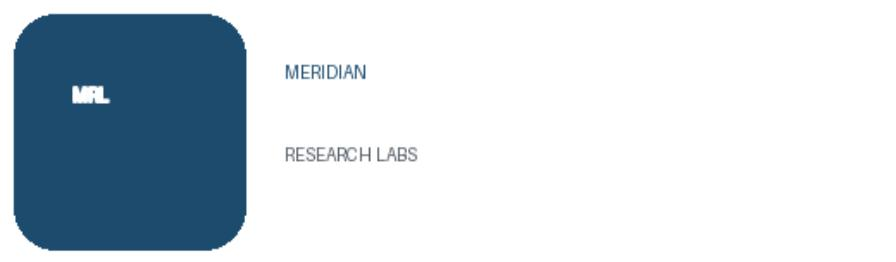

,modality,source_doc,page,similarity,content
0,image,sample_multimodal_invoice.pdf,NaN,0.7867,a blue and white graphic with the words medium...
1,text,sample_multimodal_invoice.pdf,2.0,0.7116,Document Control
2,text,sample_multimodal_invoice.pdf,1.0,0.7108,Grand Total
3,text,sample_multimodal_invoice.pdf,1.0,0.7101,Original for recipient
4,text,sample_multimodal_invoice.pdf,2.0,0.7081,Synthetic sample document — for notebook testing
5,text,sample_multimodal_invoice.pdf,1.0,0.7081,Synthetic sample document — for notebook testing
6,text,sample_multimodal_invoice.pdf,1.0,0.7056,. Bank details: Meridian Research Labs Pvt. Lt...
7,text,sample_multimodal_invoice.pdf,2.0,0.7042,Service Summary


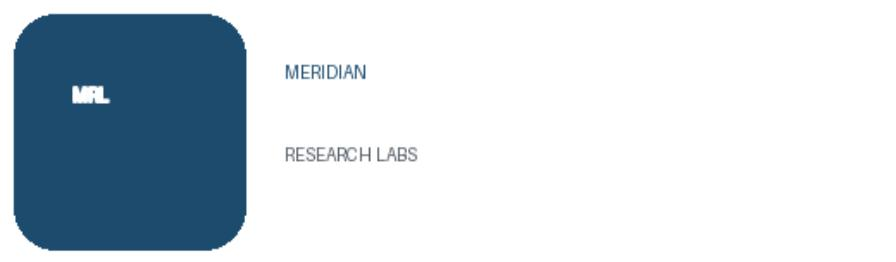

In [18]:
query_upload = files.upload()
query_image_files = [
    name for name in query_upload
    if Path(name).suffix.lower() in image_extensions
]
if not query_image_files:
    raise ValueError("Upload an image for the text-plus-image query.")

query_image = Image.open(query_image_files[0]).convert("RGB")
display(query_image)

multimodal_query_text = "Find document content related to this image."
text_vector = embed_text_query(multimodal_query_text)
image_vector = embed_image_query(query_image)
combined_vector = 0.5 * text_vector + 0.5 * image_vector
combined_vector = combined_vector / np.linalg.norm(combined_vector, axis=1, keepdims=True)

multimodal_results = search_index(combined_vector, top_k=8)
display_results(multimodal_results)

## 16. Prepare retrieved context and source IDs

Select the text-only or text-plus-image results and assign source IDs for traceable generation.

In [19]:
generation_mode = "text_plus_image"  # "text_only" or "text_plus_image"
selected_results = text_results if generation_mode == "text_only" else multimodal_results

context_items = []
for i, record in enumerate(selected_results, start=1):
    item = record.copy()
    item["source_id"] = f"S{i}"
    context_items.append(item)

context_text = "\\n\\n".join(
    f"[{item['source_id']}] Modality: {item['modality']} | "
    f"Document: {item['source_doc']} | Page: {item['page']}\\n"
    f"Content: {item['text']}"
    for item in context_items
)

display(pd.DataFrame([
    {"source_id": r["source_id"], "modality": r["modality"],
     "source_doc": r["source_doc"], "page": r["page"],
     "similarity": r["similarity"], "content": r["text"]}
    for r in context_items
]))

,source_id,modality,source_doc,page,similarity,content
0,S1,image,sample_multimodal_invoice.pdf,NaN,0.7867,a blue and white graphic with the words medium...
1,S2,text,sample_multimodal_invoice.pdf,2.0,0.7116,Document Control
2,S3,text,sample_multimodal_invoice.pdf,1.0,0.7108,Grand Total
3,S4,text,sample_multimodal_invoice.pdf,1.0,0.7101,Original for recipient
4,S5,text,sample_multimodal_invoice.pdf,2.0,0.7081,Synthetic sample document — for notebook testing
5,S6,text,sample_multimodal_invoice.pdf,1.0,0.7081,Synthetic sample document — for notebook testing
6,S7,text,sample_multimodal_invoice.pdf,1.0,0.7056,. Bank details: Meridian Research Labs Pvt. Lt...
7,S8,text,sample_multimodal_invoice.pdf,2.0,0.7042,Service Summary


## 17. Load Qwen3-VL

Load Qwen3-VL-4B-Instruct to generate answers from retrieved text and visual evidence. A GPU with sufficient memory is recommended.

In [1]:
vlm_model_id = "Qwen/Qwen3-VL-4B-Instruct"
vlm_processor = AutoProcessor.from_pretrained(vlm_model_id)
vlm_model = Qwen3VLForConditionalGeneration.from_pretrained(
    vlm_model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None
)
if device == "cpu":
    vlm_model = vlm_model.to(device)

print("Loaded:", vlm_model_id)

NameError: name 'AutoProcessor' is not defined

## 18. Generate a grounded answer

Pass retrieved text and the actual retrieved images to Qwen3-VL. Require source citations and an explicit statement when evidence is missing.

In [ ]:
from qwen_vl_utils import process_vision_info

visual_results = [
    item for item in context_items
    if item.get("image_path") and Path(item["image_path"]).exists()
][:3]

question = "What equipment and services are listed in the document, and what is the invoice total?"
instructions = (
    "Answer only from the retrieved evidence and attached images. Do not guess. "
    "If a requested detail is not supported, say it is not present in the retrieved context. "
    "Cite every factual claim using source IDs such as [S1] or [S2]. "
    "Do not invent page numbers or source IDs."
)

content = [{
    "type": "text",
    "text": instructions + "\\n\\nRetrieved context:\\n" + context_text
}]
for item in visual_results:
    content.append({"type": "image", "image": item["image_path"]})
content.append({"type": "text", "text": "\\nQuestion: " + question})

messages = [{"role": "user", "content": content}]
prompt = vlm_processor.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
)
image_inputs, video_inputs = process_vision_info(messages)

inputs = vlm_processor(
    text=[prompt], images=image_inputs, videos=video_inputs,
    padding=True, return_tensors="pt"
).to(vlm_model.device)

with torch.inference_mode():
    generated = vlm_model.generate(**inputs, max_new_tokens=400)

trimmed = [
    output_ids[len(input_ids):]
    for input_ids, output_ids in zip(inputs.input_ids, generated)
]
answer = vlm_processor.batch_decode(
    trimmed, skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)[0]

print(answer)

## 19. Check citations and inspect provenance

Check that the answer refers only to source IDs that exist in the retrieved context, then review the cited records.

In [ ]:
used_ids = sorted(set(re.findall(r"\\[(S\\d+)\\]", answer)))
valid_ids = {item["source_id"] for item in context_items}
unknown_ids = [source_id for source_id in used_ids if source_id not in valid_ids]

print("Citation IDs used:", used_ids)
print("Unknown citation IDs:", unknown_ids)
print("Citation ID check:", "PASS" if used_ids and not unknown_ids else "REVIEW")

display(pd.DataFrame([
    {"source_id": item["source_id"], "source_doc": item["source_doc"],
     "page": item["page"], "modality": item["modality"], "content": item["text"]}
    for item in context_items
]))

## 20. Save pipeline outputs

Save extracted elements, chunks, captions, index metadata, and the generated answer so the full pipeline has reusable outputs.

In [ ]:
output_dir = Path("multimodal_rag_outputs")
output_dir.mkdir(exist_ok=True)

with open(output_dir / "document_elements.json", "w", encoding="utf-8") as f:
    json.dump(element_records, f, ensure_ascii=False, indent=2, default=str)
with open(output_dir / "text_chunks.json", "w", encoding="utf-8") as f:
    json.dump(text_chunks, f, ensure_ascii=False, indent=2)
with open(output_dir / "image_captions.json", "w", encoding="utf-8") as f:
    json.dump([
        {"image_id": item["image_id"], "source_doc": item["source_doc"],
         "image_path": item["image_path"], "caption": item.get("caption")}
        for item in image_items
    ], f, ensure_ascii=False, indent=2)
faiss.write_index(index, str(output_dir / "multimodal_faiss.index"))
with open(output_dir / "index_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
with open(output_dir / "grounded_answer.json", "w", encoding="utf-8") as f:
    json.dump({
        "question": question, "answer": answer, "generation_mode": generation_mode,
        "used_source_ids": used_ids, "unknown_source_ids": unknown_ids,
        "sources": context_items
    }, f, ensure_ascii=False, indent=2, default=str)

print("Saved pipeline outputs to:", output_dir)

## 21. Download key outputs

Download the FAISS index, metadata, and grounded answer for the Module 6 deliverable.

In [ ]:
files.download(str(output_dir / "multimodal_faiss.index"))
files.download(str(output_dir / "index_metadata.json"))
files.download(str(output_dir / "grounded_answer.json"))

## Notebook summary

This notebook assembles the Module 6 workflow into one non-agentic multimodal RAG pipeline. It ingests a PDF, extracts layout elements and visual regions with metadata, chunks text and tables, captions images with BLIP-2, and creates CLIP embeddings for text, captions, and images. It indexes those vectors in FAISS, retrieves context from text-only and text-plus-image queries, and uses Qwen3-VL to generate an answer with source IDs. The notebook saves the extracted data, index, metadata, and grounded answer. Citation-ID checks confirm that references exist; they do not prove that every answer claim is factually correct, so the cited pages must still be reviewed.